# Tutorial: from a catalogue to ages

This is a short tutorial to show how to infer ages, distances and extinctions for a handful of stars. It also shows how to identify when the pipeline has failed/produced unreliable results.


| Step | |
|---|---|
| 1 | Look at your table |
| 2 | Make the **columns file**: your column names → DECIMA's |
| 3 | Check everything before running |
| 4 | Choose the **settings** |
| 5 | Run |
| 6 | Read the summary, the samples and the rejected stars |
| 7 | Spot a star you should not trust |

## Install

```bash
git clone https://github.com/teresa-su/decima && cd decima
uv sync --group dev        # or: pip install -e .
```

The first time DECIMA runs inference it downloads the trained models ([doi:10.5281/zenodo.24584265](https://doi.org/10.5281/zenodo.24584265), CC-BY-4.0, 245 MB) from Zenodo and caches them (`~/.cache/decima/v1` on Linux). If your compute nodes have no internet, run `decima download-models` on the login node first. To keep the models elsewhere, or use a copy you already have, set `DECIMA_DATA_DIR` to that directory.

In [1]:
import warnings

warnings.filterwarnings("ignore", message=".*triangular_solve.*")  # harmless warnings from dependencies
warnings.filterwarnings("ignore", message=".*IProgress.*")

import matplotlib.pyplot as plt
from astropy.table import Table

import decima

## 1. Look at your table

`data/example_stars.ecsv` has seven stars with spectroscopy (LAMOST-style names), Gaia and 2MASS photometry. Five are real stars from the Xiang+24 catalogue. Two are copies altered for this tutorial: one has no T_eff, and one has a parallax that does not fit its spectroscopy. DECIMA reads any table astropy reads (FITS, CSV, ECSV, ...) and also pandas data frames.

In [2]:
stars = Table.read("data/example_stars.ecsv")
print(stars.colnames)
stars["GAIAEDR3_SOURCE_ID_1", "TEFF", "FEH", "PARALLAX", "E_PARALLAX", "TWOMASS_K"]

['GAIAEDR3_SOURCE_ID_1', 'RAJ2000', 'DEJ2000', 'GAIA_G', 'GAIA_BP', 'GAIA_RP', 'E_GAIA_G', 'E_GAIA_BP', 'E_GAIA_RP', 'TWOMASS_J', 'TWOMASS_H', 'TWOMASS_K', 'j_msigcom', 'h_msigcom', 'ks_msigcom', 'PARALLAX', 'E_PARALLAX', 'TEFF', 'E_TEFF', 'LOGG', 'E_LOGG', 'FEH', 'E_FEH', 'ALPHA_FE', 'E_ALPHA_FE']


GAIAEDR3_SOURCE_ID_1,TEFF,FEH,PARALLAX,E_PARALLAX,TWOMASS_K
int64,float64,float64,float64,float64,float64
252151452574542848,6260.75048828125,-0.19183669984340668,1.113739252090454,0.016663771122694016,11.407999992370605
680764209182123904,5199.55712890625,-0.15742628276348114,1.0352951288223267,0.015812484547495842,11.618000030517578
1833814597182212480,6321.8896484375,-0.18951481580734253,0.7682903409004211,0.013188771903514862,11.187000274658203
2101797054382004480,6165.13525390625,-0.004442123696208,0.6353513598442078,0.010229725390672684,12.065999984741211
4424101195767543936,5697.90869140625,-0.5038778781890869,0.3740552067756653,0.03859952464699745,14.307999610900879
1,nan,-0.19183669984340668,1.113739252090454,0.016663771122694016,11.407999992370605
2,5199.55712890625,-0.15742628276348114,0.25882378220558167,0.015812484547495842,11.618000030517578


## 2. Make the columns file

DECIMA has its own names for the columns it needs (`teff`, `feh`, `parallax`, `Ks`, ... see the [input reference](reference/inputs.md)). If your table calls them something else, the **columns file** will provide the mapping: *DECIMA's name → table name*.

You do not have to write it by hand. `suggest_columns` (on the shell: `decima columns stars.ecsv -o cols.json`) matches names for you:

In [3]:
suggestion = decima.suggest_columns(stars)
print(suggestion)

  ok  id                         <- 'GAIAEDR3_SOURCE_ID_1'
  ok  ra                         <- 'RAJ2000'
  ok  dec                        <- 'DEJ2000'
  ok  parallax                   <- 'PARALLAX'
  ok  parallax_error             <- 'E_PARALLAX'
  ok  teff                       <- 'TEFF'
  ok  teff_error                 <- 'E_TEFF'
  ok  feh                        <- 'FEH'
  ok  feh_error                  <- 'E_FEH'
  ok  alpha_fe                   <- 'ALPHA_FE'
  ok  alpha_fe_error             <- 'E_ALPHA_FE'
  ok  logg                       <- 'LOGG'
  ok  logg_error                 <- 'E_LOGG'
  ok  G                          <- 'GAIA_G'
  ok  BP                         <- 'GAIA_BP'
  ok  RP                         <- 'GAIA_RP'
  ok  J                          <- 'TWOMASS_J'
  ok  H                          <- 'TWOMASS_H'
  ok  Ks                         <- 'TWOMASS_K'
  ok  G_error                    <- 'E_GAIA_G'
  ok  BP_error                   <- 'E_GAIA_BP'
  ok  RP_error     

`ok` rows were matched. If a required column is `NOT FOUND`, or two columns could both be the answer (`??`), DECIMA says so instead of guessing: [Make your columns file](how-to/config-files.ipynb) shows how to fix those. Here everything was found, so the columns file is just the suggestion:

In [4]:
columns = dict(suggestion)
columns

{'id': 'GAIAEDR3_SOURCE_ID_1',
 'ra': 'RAJ2000',
 'dec': 'DEJ2000',
 'parallax': 'PARALLAX',
 'parallax_error': 'E_PARALLAX',
 'teff': 'TEFF',
 'teff_error': 'E_TEFF',
 'feh': 'FEH',
 'feh_error': 'E_FEH',
 'alpha_fe': 'ALPHA_FE',
 'alpha_fe_error': 'E_ALPHA_FE',
 'logg': 'LOGG',
 'logg_error': 'E_LOGG',
 'G': 'GAIA_G',
 'BP': 'GAIA_BP',
 'RP': 'GAIA_RP',
 'J': 'TWOMASS_J',
 'H': 'TWOMASS_H',
 'Ks': 'TWOMASS_K',
 'G_error': 'E_GAIA_G',
 'BP_error': 'E_GAIA_BP',
 'RP_error': 'E_GAIA_RP',
 'J_error': 'j_msigcom',
 'H_error': 'h_msigcom',
 'Ks_error': 'ks_msigcom'}

## 3. Check before you run

`check_inputs` (shell: `decima check stars.ecsv --columns cols.json`) reads your table and the columns file and reports what would go wrong, including values that look like the wrong unit (log T_eff instead of K, parallax in arcsec, `99` as a "missing" magnitude).

In [5]:
print(decima.check_inputs(stars, columns))

DECIMA input check: Table (7 rows)
Columns used:
  id                         <- 'GAIAEDR3_SOURCE_ID_1'
  ra                         <- 'RAJ2000'
  dec                        <- 'DEJ2000'
  parallax                   <- 'PARALLAX'
  parallax_error             <- 'E_PARALLAX'
  teff                       <- 'TEFF'
  teff_error                 <- 'E_TEFF'
  feh                        <- 'FEH'
  feh_error                  <- 'E_FEH'
  alpha_fe                   <- 'ALPHA_FE'
  alpha_fe_error             <- 'E_ALPHA_FE'
  logg                       <- 'LOGG'
  logg_error                 <- 'E_LOGG'
  G                          <- 'GAIA_G'
  BP                         <- 'GAIA_BP'
  RP                         <- 'GAIA_RP'
  J                          <- 'TWOMASS_J'
  H                          <- 'TWOMASS_H'
  Ks                         <- 'TWOMASS_K'
  G_error                    <- 'E_GAIA_G'
  BP_error                   <- 'E_GAIA_BP'
  RP_error                   <- 'E_GAIA_RP'
  J_error 

Read the end of the report: six of the seven stars can be run, and one is rejected for having no T_eff.

## 4. Choose the settings

Everything that changes the result is in `decima.Config`; the defaults are the ones DECIMA was validated with. The **settings file** is a different file from the columns file: it holds these settings, not column names. Change what you need and leave the rest:

In [6]:
cfg = decima.Config(n_keep=1000)  # keep 1000 posterior samples per star instead of 400
print(cfg.to_json()[:300], "...")

{
  "n_latent_x": 800,
  "n_theta": 10,
  "n_keep": 1000,
  "percentiles": [
    5,
    16,
    50,
    84,
    95
  ],
  "seed": 22,
  "mixture_alpha": 0.1,
  "npe_ratio_ceiling": 1.0,
  "imf_prior": true,
  "use_logg": false,
  "bands": [
    "G",
    "BP",
    "RP",
    "J",
    "H",
    "Ks"
  ] ...


On the shell: `decima default-config > settings.json`, edit it, and pass it with `--config settings.json`. A misspelt setting or an impossible value is refused before any computation, and the message says how to fix it. See the [settings reference](reference/settings.md) for all of them.

## 5. Run

In [7]:
summary, samples, rejected = decima.infer(stars, columns, cfg)
len(summary), samples.shape

(6, (6, 1000, 7))

`infer` is for notebooks and up to a few thousand stars. For a big catalogue, the same inputs go to `decima run` on the shell, which works in chunks, uses several processes and resumes if interrupted: see [Run a large catalogue](how-to/large-runs.md).

## 6. Read the results

**`summary`** has one row per star that was run. For every quantity it has percentiles (5, 16, 50, 84, 95): `age_p16`, `age_p50`, `age_p84` give the median age and a 68% interval, in Gyr.

In [8]:
summary["id", "age_p16", "age_p50", "age_p84", "distance_p50", "A0_p50", "ess_frac", "failed"]

id,age_p16,age_p50,age_p84,distance_p50,A0_p50,ess_frac,failed
int64,float32,float32,float32,float32,float32,float32,bool
252151452574542848,2.7233915,2.8887982,3.0682976,895.7958,2.0888846,0.021809379,False
680764209182123904,7.121547,7.8273845,8.651964,966.8385,0.2525234,0.044595376,False
1833814597182212480,1.3779565,1.4203247,1.4482319,1299.9564,1.9857078,0.006124422,False
2101797054382004480,2.3750947,2.5476644,2.6725783,1570.834,0.31869516,0.020600453,False
4424101195767543936,8.424949,10.226062,12.514869,2571.0017,0.14326273,0.20779729,False
2,0.707036,0.7590077,0.7787387,3755.2292,0.19750902,0.001611154,False


**`samples`** has the posterior draws themselves, shape `(stars, n_keep, 7)`. The seven quantities, in order, are:

In [9]:
decima.quantity_names(cfg)

('feh_init', 'alpha_fe_init', 'log_age', 'eep', 'age', 'distance', 'A0')

**`rejected`** lists the rows that could not be run, and why. They are not in the summary, which is why `id` matters: map an `id` column to match results to your table.

In [10]:
rejected

row,id,reason
int64,int64,str7
5,1,no teff


## 7. Spot a star you should not trust

`failed` flags stars with no usable result. None failed here. But a star can come out without being flagged and still be doubtful. `ess_frac` is the effective sample size of the final weights as a fraction of the draws DECIMA made. A small value means the photometry and parallax disagree with what the spectroscopy predicts.

In [11]:
summary["ess"] = summary["ess_frac"] * cfg.n_latent_x * cfg.n_theta
summary["id", "ess_frac", "ess", "age_p50"]

id,ess_frac,ess,age_p50
int64,float32,float32,float32
252151452574542848,0.021809379,174.47502,2.8887982
680764209182123904,0.044595376,356.763,7.8273845
1833814597182212480,0.006124422,48.995377,1.4203247
2101797054382004480,0.020600453,164.80362,2.5476644
4424101195767543936,0.20779729,1662.3782,10.226062
2,0.001611154,12.889232,0.7590077


The star with `id = 2` has the lowest effective sample size (about 13 of 8000 draws): its parallax was changed to a quarter of the real one. It is a copy of the star with `id = 680764209182123904`, so the spectroscopy is the same, yet the ages disagree (0.8 Gyr against 7.8 Gyr). Compare the two posteriors:

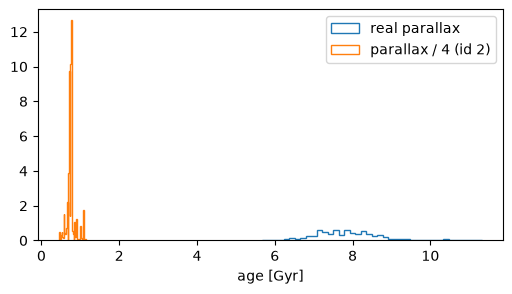

In [12]:
ids = list(summary["id"])
real, altered = ids.index(680764209182123904), ids.index(2)
fig, ax = plt.subplots(figsize=(6, 3))
age = decima.quantity_names(cfg).index("age")
for k, label in ((real, "real parallax"), (altered, "parallax / 4 (id 2)")):
    ax.hist(samples[k, :, age], bins=40, histtype="step", density=True, label=label)
ax.set_xlabel("age [Gyr]")
ax.legend();

Use `failed` and `ess_frac` as a first filter, then look at the stars it leaves you with. [Decide which results to trust](how-to/trust-results.md) says what else to look at and which stars DECIMA was validated on.

## Where next

- Your own catalogue: [Make your columns file](how-to/config-files.ipynb), then [Run a large catalogue](how-to/large-runs.md).
- What DECIMA does with your numbers: [How DECIMA works](explanation/method.md).